# Sprint 1 — Análise do tempo de processamento do Pix

**Variável:** `Tempo_processamento_seg`  
**Unidade:** segundos  
**Etapas:** Planilha 1 (antes, 300 observações) e Planilha 2 (depois, 100 observações).

A sequência de células acompanha o tutorial [Python — Distribuição Normal](refs/Python%20-%20Distribui%C3%A7%C3%A3o%20Normal-1-1.pdf). A leitura, os gráficos e as medidas seguem o padrão de código do material. Os limites de referência destacados como provisórios precisam de justificativa do grupo no relatório manual.

## 1. Importar as bibliotecas

In [1]:
import pandas as pd
import math
import seaborn as sns
import matplotlib.pyplot as plt

## 2. Definir as variáveis `arquivo` e `coluna`

In [2]:
arquivo = "../Refs/Planilha 1 - TEMPO PAGAMENTO PIX.xlsx"
arquivo_depois = "../Refs/Planilha 2 -TEMPO PAGAMENTO PIX-2.xlsx"
coluna = "Tempo_processamento_seg"

## 3. Leitura do arquivo de dados — Planilha 1 (antes da intervenção)

In [3]:
df_antes = pd.read_excel(arquivo)
df_antes

,Tempo_processamento_seg
0,1.47
1,1.48
2,1.61
3,1.67
4,1.69
...,...
295,3.40
296,3.40
297,3.41
298,3.42


### Leitura da Planilha 2 (depois da intervenção)

In [4]:
df_depois = pd.read_excel(arquivo_depois)
df_depois

,Tempo_processamento_seg
0,3.01
1,3.47
2,3.67
3,3.68
4,3.75
...,...
95,6.54
96,6.57
97,6.61
98,6.84


### Conferência das dimensões e da coluna

In [5]:
quantidade_esperada_antes = 300
quantidade_esperada_depois = 100

for nome, dados, quantidade_esperada in [
    ("Planilha 1 — antes", df_antes, quantidade_esperada_antes),
    ("Planilha 2 — depois", df_depois, quantidade_esperada_depois),
]:
    if coluna not in dados.columns:
        raise KeyError(f"A coluna {coluna!r} não existe em {nome}.")
    if dados[coluna].isna().any():
        raise ValueError(f"Há valores ausentes em {nome}.")
    if not pd.api.types.is_numeric_dtype(dados[coluna]):
        raise TypeError(f"A coluna {coluna!r} precisa ser numérica em {nome}.")
    if len(dados) != quantidade_esperada:
        raise ValueError(
            f"{nome}: esperado {quantidade_esperada} registros; "
            f"encontrado {len(dados)}."
        )
    print(f"{nome}: {len(dados)} observações — conferido.")

Planilha 1 — antes: 300 observações — conferido.
Planilha 2 — depois: 100 observações — conferido.


## Questão 1 — contextualização do problema

**Preencher manualmente no relatório:** contexto do processo Pix, problema investigado, possível causa, importância do tempo de processamento e justificativa dos valores de referência. Esses elementos não estão descritos nas planilhas ou nos materiais disponíveis.

## Questão 2 — gráficos dos dados anteriores à intervenção

### 4. Gerar o histograma e o boxplot para a variável contínua

#### 4.1 Representação do histograma com a curva normal

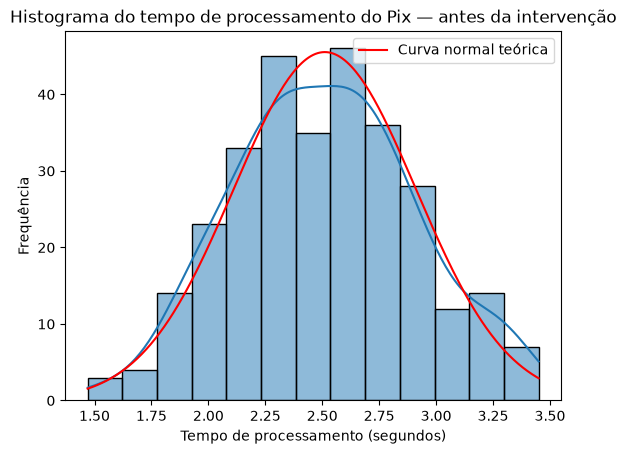

In [6]:
media_curva = df_antes[coluna].mean()
desvio_curva = df_antes[coluna].std()

eixo = sns.histplot(data=df_antes[coluna], kde=True)

# Curva normal teórica (média e desvio-padrão da Planilha 1), escalada para frequência
largura_classe = eixo.patches[0].get_width()
minimo, maximo = df_antes[coluna].min(), df_antes[coluna].max()
x_curva = [minimo + i * (maximo - minimo) / 200 for i in range(201)]
y_curva = [
    len(df_antes[coluna]) * largura_classe
    * math.exp(-((x - media_curva) ** 2) / (2 * desvio_curva ** 2))
    / (desvio_curva * math.sqrt(2 * math.pi))
    for x in x_curva
]
plt.plot(x_curva, y_curva, color="red", label="Curva normal teórica")

plt.title("Histograma do tempo de processamento do Pix — antes da intervenção")
plt.xlabel("Tempo de processamento (segundos)")
plt.ylabel("Frequência")
plt.legend()
plt.show()

#### 4.2 Boxplot

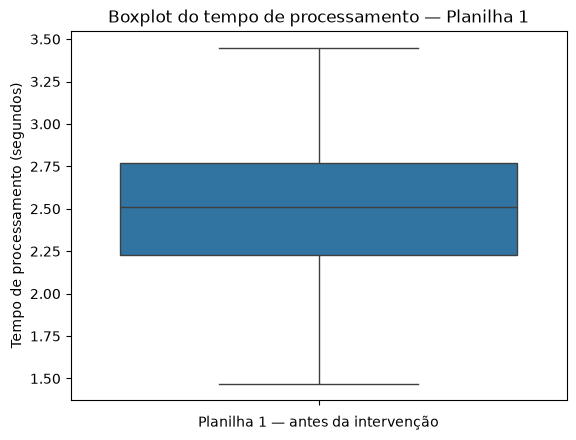

In [7]:
sns.boxplot(data=df_antes[coluna])
plt.title("Boxplot do tempo de processamento — Planilha 1")
plt.xlabel("Planilha 1 — antes da intervenção")
plt.ylabel("Tempo de processamento (segundos)")
plt.show()

## Questão 3 — média e desvio-padrão dos dados anteriores

### 5. Cálculo da Média, Mediana e do Desvio Padrão

#### Média

In [8]:
media_antes = df_antes[coluna].mean()
print(f"Média antes da intervenção: {media_antes:.2f} segundos")

Média antes da intervenção: 2.51 segundos


#### Mediana

In [9]:
mediana_antes = df_antes[coluna].median()
print(f"Mediana antes da intervenção: {mediana_antes:.2f} segundos")

Mediana antes da intervenção: 2.51 segundos


#### Desvio-padrão amostral

In [10]:
desvio_padrao_antes = df_antes[coluna].std()
print(f"Desvio-padrão antes da intervenção: {desvio_padrao_antes:.2f} segundos")

Desvio-padrão antes da intervenção: 0.40 segundos


## Questão 4 — testes de normalidade

### 6. Testes de Normalidade

#### 6.1 Análise do histograma

Observe se existe um único pico e se ele fica próximo da média e da mediana. Compare também as proporções nos intervalos de um, dois e três desvios-padrão com a regra empírica aproximada de 68%, 95% e 99%.

##### Definir os limites dos intervalos

In [11]:
limite_inf_1dp = round(media_antes - desvio_padrao_antes, 2)
limite_sup_1dp = round(media_antes + desvio_padrao_antes, 2)
limite_inf_2dp = round(media_antes - 2 * desvio_padrao_antes, 2)
limite_sup_2dp = round(media_antes + 2 * desvio_padrao_antes, 2)
limite_inf_3dp = round(media_antes - 3 * desvio_padrao_antes, 2)
limite_sup_3dp = round(media_antes + 3 * desvio_padrao_antes, 2)

print(f"±1 desvio-padrão: [{limite_inf_1dp}, {limite_sup_1dp}] segundos")
print(f"±2 desvios-padrão: [{limite_inf_2dp}, {limite_sup_2dp}] segundos")
print(f"±3 desvios-padrão: [{limite_inf_3dp}, {limite_sup_3dp}] segundos")

±1 desvio-padrão: [2.11, 2.91] segundos
±2 desvios-padrão: [1.71, 3.31] segundos
±3 desvios-padrão: [1.31, 3.71] segundos


##### Quantidade de observações no intervalo de um desvio-padrão

In [12]:
quantidade_1dp = int(sum(
    limite_inf_1dp <= valor <= limite_sup_1dp
    for valor in df_antes[coluna].sort_values()
))
print(f"Observações em ±1 desvio-padrão: {quantidade_1dp}")

Observações em ±1 desvio-padrão: 204


##### Quantidade de observações no intervalo de dois desvios-padrão

In [13]:
quantidade_2dp = int(sum(
    limite_inf_2dp <= valor <= limite_sup_2dp
    for valor in df_antes[coluna].sort_values()
))
print(f"Observações em ±2 desvios-padrão: {quantidade_2dp}")

Observações em ±2 desvios-padrão: 288


##### Quantidade de observações no intervalo de três desvios-padrão

In [14]:
quantidade_3dp = int(sum(
    limite_inf_3dp <= valor <= limite_sup_3dp
    for valor in df_antes[coluna].sort_values()
))
print(f"Observações em ±3 desvios-padrão: {quantidade_3dp}")

Observações em ±3 desvios-padrão: 300


##### Porcentagens observadas e comparação com a regra empírica

In [15]:
total_antes = len(df_antes[coluna])

porcentagem_1dp = round(quantidade_1dp / total_antes * 100, 2)
porcentagem_2dp = round(quantidade_2dp / total_antes * 100, 2)
porcentagem_3dp = round(quantidade_3dp / total_antes * 100, 2)

print(f"±1 desvio-padrão: {porcentagem_1dp:.2f}% (regra empírica ≈ 68%)")
print(f"±2 desvios-padrão: {porcentagem_2dp:.2f}% (regra empírica ≈ 95%)")
print(f"±3 desvios-padrão: {porcentagem_3dp:.2f}% (regra empírica ≈ 99,7%)")

±1 desvio-padrão: 68.00% (regra empírica ≈ 68%)
±2 desvios-padrão: 96.00% (regra empírica ≈ 95%)
±3 desvios-padrão: 100.00% (regra empírica ≈ 99,7%)


**Interpretação breve:** O histograma apresenta um pico principal próximo à média e à mediana. As proporções observadas — 68%, 96% e 100% dentro de 1, 2 e 3 desvios-padrão — ficam próximas da regra empírica (68%, 95% e 99%), o que apoia uma compatibilidade aproximada com a distribuição normal.

#### 6.2 Análise da simetria do boxplot

Compare as distâncias entre `Q2 − Q1` e `Q3 − Q2`.

In [16]:
q1_antes = df_antes[coluna].quantile(0.25)
q2_antes = df_antes[coluna].quantile(0.50)
q3_antes = df_antes[coluna].quantile(0.75)

metade_inferior_antes = q2_antes - q1_antes
metade_superior_antes = q3_antes - q2_antes

print(f"Q1: {q1_antes:.2f} segundos")
print(f"Q2 (mediana): {q2_antes:.2f} segundos")
print(f"Q3: {q3_antes:.2f} segundos")
print(f"Q2 − Q1: {metade_inferior_antes:.2f} segundos")
print(f"Q3 − Q2: {metade_superior_antes:.2f} segundos")

Q1: 2.23 segundos
Q2 (mediana): 2.51 segundos
Q3: 2.77 segundos
Q2 − Q1: 0.28 segundos
Q3 − Q2: 0.26 segundos


**Interpretação breve:** As metades do boxplot medem aproximadamente 0,28 s e 0,26 s. Como são próximas, os quartis sugerem simetria aproximada, sem exigir que a distribuição seja perfeitamente simétrica.

#### 6.3 Diagrama Q-Q

O tutorial compara os quantis observados com os teóricos e acrescenta uma linha de referência. A CDF e a inversa da normal abaixo são calculadas com `math`, mantendo as dependências permitidas no projeto.

In [17]:
def cdf_normal_padrao(z):
    return (1 + math.erf(z / math.sqrt(2))) / 2


def quantil_normal_padrao(probabilidade):
    if not 0 < probabilidade < 1:
        raise ValueError("A probabilidade deve estar entre 0 e 1.")

    limite_inferior = -8.0
    limite_superior = 8.0

    for _ in range(80):
        ponto_medio = (limite_inferior + limite_superior) / 2
        if cdf_normal_padrao(ponto_medio) < probabilidade:
            limite_inferior = ponto_medio
        else:
            limite_superior = ponto_medio

    return (limite_inferior + limite_superior) / 2

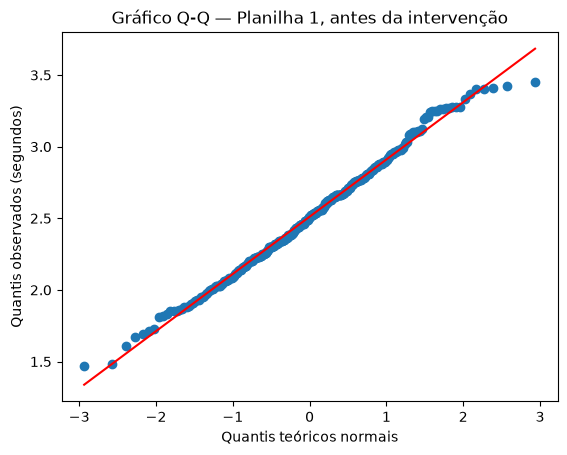

In [18]:
dados_ordenados_antes = df_antes[coluna].sort_values().tolist()
quantidade_antes = len(dados_ordenados_antes)
quantis_teoricos_antes = [
    quantil_normal_padrao((i - 0.5) / quantidade_antes)
    for i in range(1, quantidade_antes + 1)
]

media_teorica = sum(quantis_teoricos_antes) / quantidade_antes
media_observada = sum(dados_ordenados_antes) / quantidade_antes
inclinacao = sum(
    (x - media_teorica) * (y - media_observada)
    for x, y in zip(quantis_teoricos_antes, dados_ordenados_antes)
) / sum((x - media_teorica) ** 2 for x in quantis_teoricos_antes)
intercepto = media_observada - inclinacao * media_teorica

x_linha = [min(quantis_teoricos_antes), max(quantis_teoricos_antes)]
y_linha = [intercepto + inclinacao * x for x in x_linha]

plt.scatter(quantis_teoricos_antes, dados_ordenados_antes)
plt.plot(x_linha, y_linha, color="red")
plt.title("Gráfico Q-Q — Planilha 1, antes da intervenção")
plt.xlabel("Quantis teóricos normais")
plt.ylabel("Quantis observados (segundos)")
plt.show()

**Interpretação breve:** Os pontos do Q-Q acompanham aproximadamente a reta de referência, com pequenos desvios nas caudas. Junto ao histograma, à regra empírica e aos quartis, isso é compatível com normalidade aproximada para esta análise.

## 7. Calculando a Probabilidade em Intervalos (Questão 5)

**Intervalo provisório para habilitar os cálculos:** `[2, 3]` segundos. As planilhas e orientações não fornecem um limite operacional para o processo Pix; o grupo deve justificar manualmente essa faixa no contexto do problema ou substituí-la após orientação docente.

In [19]:
limite_inferior_probabilidade = 2.0
limite_superior_probabilidade = 3.0

probabilidade_intervalo_antes = cdf_normal_padrao(
    (limite_superior_probabilidade - media_antes) / desvio_padrao_antes
) - cdf_normal_padrao(
    (limite_inferior_probabilidade - media_antes) / desvio_padrao_antes
)

print(
    f"Probabilidade normal de o tempo antes ficar entre "
    f"{limite_inferior_probabilidade:.1f} e "
    f"{limite_superior_probabilidade:.1f} segundos: "
    f"{probabilidade_intervalo_antes:.4f} "
    f"({probabilidade_intervalo_antes:.2%})"
)

Probabilidade normal de o tempo antes ficar entre 2.0 e 3.0 segundos: 0.7881 (78.81%)


**Interpretação breve:** Sob o modelo normal ajustado à Planilha 1, a probabilidade estimada de um tempo entre 2 e 3 s é 78,81%. Esse resultado é uma estimativa do modelo e depende de a normalidade ser uma aproximação razoável; o intervalo ainda precisa ser justificado no relatório.

## Questão 6 — limites dos 20% menores e dos 30% maiores

In [20]:
valor_maximo_20_menores = (
    media_antes + desvio_padrao_antes * quantil_normal_padrao(0.20)
)
valor_minimo_30_maiores = (
    media_antes + desvio_padrao_antes * quantil_normal_padrao(0.70)
)

print(
    f"Limite máximo dos 20% menores: "
    f"{valor_maximo_20_menores:.2f} segundos"
)
print(
    f"Limite mínimo dos 30% maiores: "
    f"{valor_minimo_30_maiores:.2f} segundos"
)

Limite máximo dos 20% menores: 2.17 segundos
Limite mínimo dos 30% maiores: 2.72 segundos


**Interpretação breve:** No modelo normal, cerca de 2,17 s é o limite superior dos 20% menores tempos, e cerca de 2,72 s é o limite inferior dos 30% maiores. São pontos de corte estimados para a distribuição da Planilha 1, em segundos.

## Questão 7.1 — situação, intervenção e objetivo

**Preencher manualmente no relatório com a intervenção real:**

- Situação-problema observada: [descrever].
- Ação de intervenção realizada: [descrever].
- Objetivo em forma de pergunta: [descrever a mudança esperada na variável].

O código usa `3.0` segundos como meta provisória de comparação, sem tratá-la como SLA ou padrão documentado.

## Questão 7.2 — gráficos dos dados posteriores à intervenção

### Histograma da Planilha 2

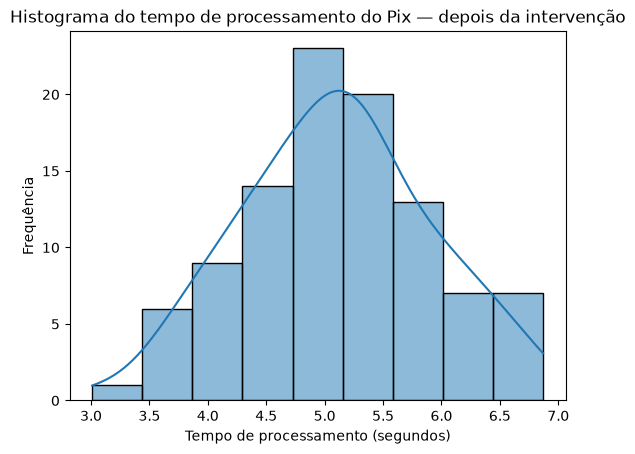

In [21]:
sns.histplot(data=df_depois[coluna], kde=True)
plt.title("Histograma do tempo de processamento do Pix — depois da intervenção")
plt.xlabel("Tempo de processamento (segundos)")
plt.ylabel("Frequência")
plt.show()

### Boxplot da Planilha 2

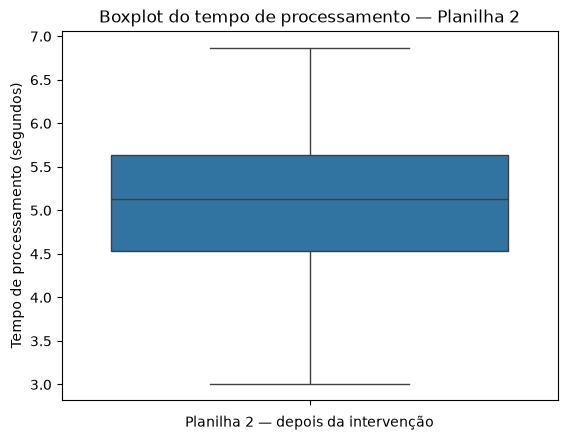

In [22]:
sns.boxplot(data=df_depois[coluna])
plt.title("Boxplot do tempo de processamento — Planilha 2")
plt.xlabel("Planilha 2 — depois da intervenção")
plt.ylabel("Tempo de processamento (segundos)")
plt.show()

## Questão 7.3 — média e desvio-padrão posteriores à intervenção

### Média

In [23]:
media_depois = df_depois[coluna].mean()
print(f"Média depois da intervenção: {media_depois:.2f} segundos")

Média depois da intervenção: 5.10 segundos


### Mediana

In [24]:
mediana_depois = df_depois[coluna].median()
print(f"Mediana depois da intervenção: {mediana_depois:.2f} segundos")

Mediana depois da intervenção: 5.12 segundos


### Desvio-padrão amostral

In [25]:
desvio_padrao_depois = df_depois[coluna].std()
print(f"Desvio-padrão depois da intervenção: {desvio_padrao_depois:.2f} segundos")

Desvio-padrão depois da intervenção: 0.81 segundos


## Questão 7.4 — quantidade de observações no intervalo escolhido

O intervalo `[2, 3]` segundos é provisório e coincide com a faixa usada na Questão 5. A pergunta e a justificativa final devem ser ajustadas à intervenção e ao objetivo que o grupo registrará manualmente.

In [26]:
quantidade_intervalo_depois = int(sum(
    limite_inferior_probabilidade <= valor <= limite_superior_probabilidade
    for valor in df_depois[coluna]
))

print(
    f"Observações da Planilha 2 entre {limite_inferior_probabilidade:.1f} e "
    f"{limite_superior_probabilidade:.1f} segundos: "
    f"{quantidade_intervalo_depois} de {len(df_depois[coluna])}"
)

Observações da Planilha 2 entre 2.0 e 3.0 segundos: 0 de 100


**Interpretação breve:** Pergunta: quantos tempos da Planilha 2 ficaram entre 2 e 3 s? Foram 0 de 100. Portanto, nenhuma observação posterior ficou nessa faixa provisória; a conclusão sobre o objetivo depende de confirmar que a faixa representa o critério real.

## Questão 8 — comparação preliminar entre os cenários

**Pergunta para o relatório manual:** há indícios de mudança no tempo de processamento entre as Planilhas 1 e 2?

Critérios provisórios alinhados a uma meta de redução:

1. Proporção de observações com tempo de até 3 segundos.
2. Proporção de observações no intervalo de 2 a 3 segundos.

Confirme a justificativa desses limites com o contexto real do problema. A comparação é descritiva e, nesta Sprint, não comprova relação causal.

In [27]:
limite_objetivo_segundos = 3.0

proporcao_criterio_1_antes = (
    df_antes[coluna] <= limite_objetivo_segundos
).mean()
proporcao_criterio_1_depois = (
    df_depois[coluna] <= limite_objetivo_segundos
).mean()

proporcao_criterio_2_antes = (
    (df_antes[coluna] >= limite_inferior_probabilidade)
    & (df_antes[coluna] <= limite_superior_probabilidade)
).mean()
proporcao_criterio_2_depois = (
    (df_depois[coluna] >= limite_inferior_probabilidade)
    & (df_depois[coluna] <= limite_superior_probabilidade)
).mean()

tabela_comparacao = pd.DataFrame(
    {
        "Critério": [
            "Até 3 segundos",
            "Entre 2 e 3 segundos",
            "Média do tempo",
            "Desvio-padrão do tempo",
        ],
        "Unidade": ["proporção", "proporção", "segundos", "segundos"],
        "Antes": [
            f"{proporcao_criterio_1_antes:.1%}",
            f"{proporcao_criterio_2_antes:.1%}",
            f"{media_antes:.2f}",
            f"{desvio_padrao_antes:.2f}",
        ],
        "Depois": [
            f"{proporcao_criterio_1_depois:.1%}",
            f"{proporcao_criterio_2_depois:.1%}",
            f"{media_depois:.2f}",
            f"{desvio_padrao_depois:.2f}",
        ],
    }
)
print(tabela_comparacao.to_string(index=False))

              Critério   Unidade Antes Depois
        Até 3 segundos proporção 89.0%   0.0%
  Entre 2 e 3 segundos proporção 79.3%   0.0%
        Média do tempo  segundos  2.51   5.10
Desvio-padrão do tempo  segundos  0.40   0.81


In [28]:
diferenca_media_segundos = media_depois - media_antes
print(
    f"Diferença descritiva entre as médias (depois − antes): "
    f"{diferenca_media_segundos:.2f} segundos"
)

if diferenca_media_segundos > 0:
    print(
        f"Na amostra, a média depois foi {diferenca_media_segundos:.2f} segundos "
        "maior; os dados não indicam redução do tempo médio."
    )
elif diferenca_media_segundos < 0:
    print(
        f"Na amostra, a média depois foi {abs(diferenca_media_segundos):.2f} segundos "
        "menor; os dados indicam redução do tempo médio."
    )
else:
    print("As médias observadas antes e depois foram iguais.")

print("Esta comparação descritiva entre amostras não comprova causalidade.")

Diferença descritiva entre as médias (depois − antes): 2.59 segundos
Na amostra, a média depois foi 2.59 segundos maior; os dados não indicam redução do tempo médio.
Esta comparação descritiva entre amostras não comprova causalidade.


**Interpretação breve:** A proporção até 3 s passou de 89% para 0%, e a proporção entre 2 e 3 s passou de 79,3% para 0%. A média subiu de 2,51 s para 5,10 s (diferença de +2,59 s). Descritivamente, os dados posteriores são mais lentos e não apontam para a redução pretendida; a comparação não demonstra causalidade.

### Resumo das respostas que seguem no relatório manual

A redação manual ainda precisa registrar o contexto e os valores de referência da Questão 1, as conclusões visuais e estatísticas da Questão 4, as interpretações das Questões 5 e 6, a intervenção e o objetivo da Questão 7.1, a pergunta da Questão 7.4 e a pergunta/conclusão da Questão 8. Os valores provisórios de `[2, 3]` segundos e da meta de `3` segundos precisam de justificativa ou substituição conforme o contexto.